# Combined block environmental burden
An explicit equal-weight scenario, not a learned or validated comfort score. Higher means less canopy and/or more nearby traffic. Weather is shared regional context and is excluded. Missing inputs remain unknown.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'scripts').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from combined_block_index import main
blocks=main()
blocks[['GEOID20','canopy_mean','traffic_index_0_100','combined_burden_0_100']].head()

{
  "formula": "100 * (0.5 * (1 - canopy_mean/100) + 0.5 * traffic_index_0_100/100)",
  "meaning": "Higher = less canopy and/or more nearby traffic; not measured danger or personal comfort.",
  "weights": "Explicit equal-weight scenario; no AI fitted these weights.",
  "missing": "Unknown if either required input is missing; never treated as zero.",
  "weather": "Shared regional weather excluded from spatial score.",
  "blocks": 2862,
  "complete_scores": 2842
}


,GEOID20,canopy_mean,traffic_index_0_100,combined_burden_0_100
0,480850320131001,1.760331,56.218190,77.228930
1,480850320121008,21.206249,16.409909,47.601830
2,480850316112014,0.906250,62.700598,80.897174
3,480850316361000,18.524794,22.487142,51.981174
4,480850316361006,19.730246,16.657782,48.463768


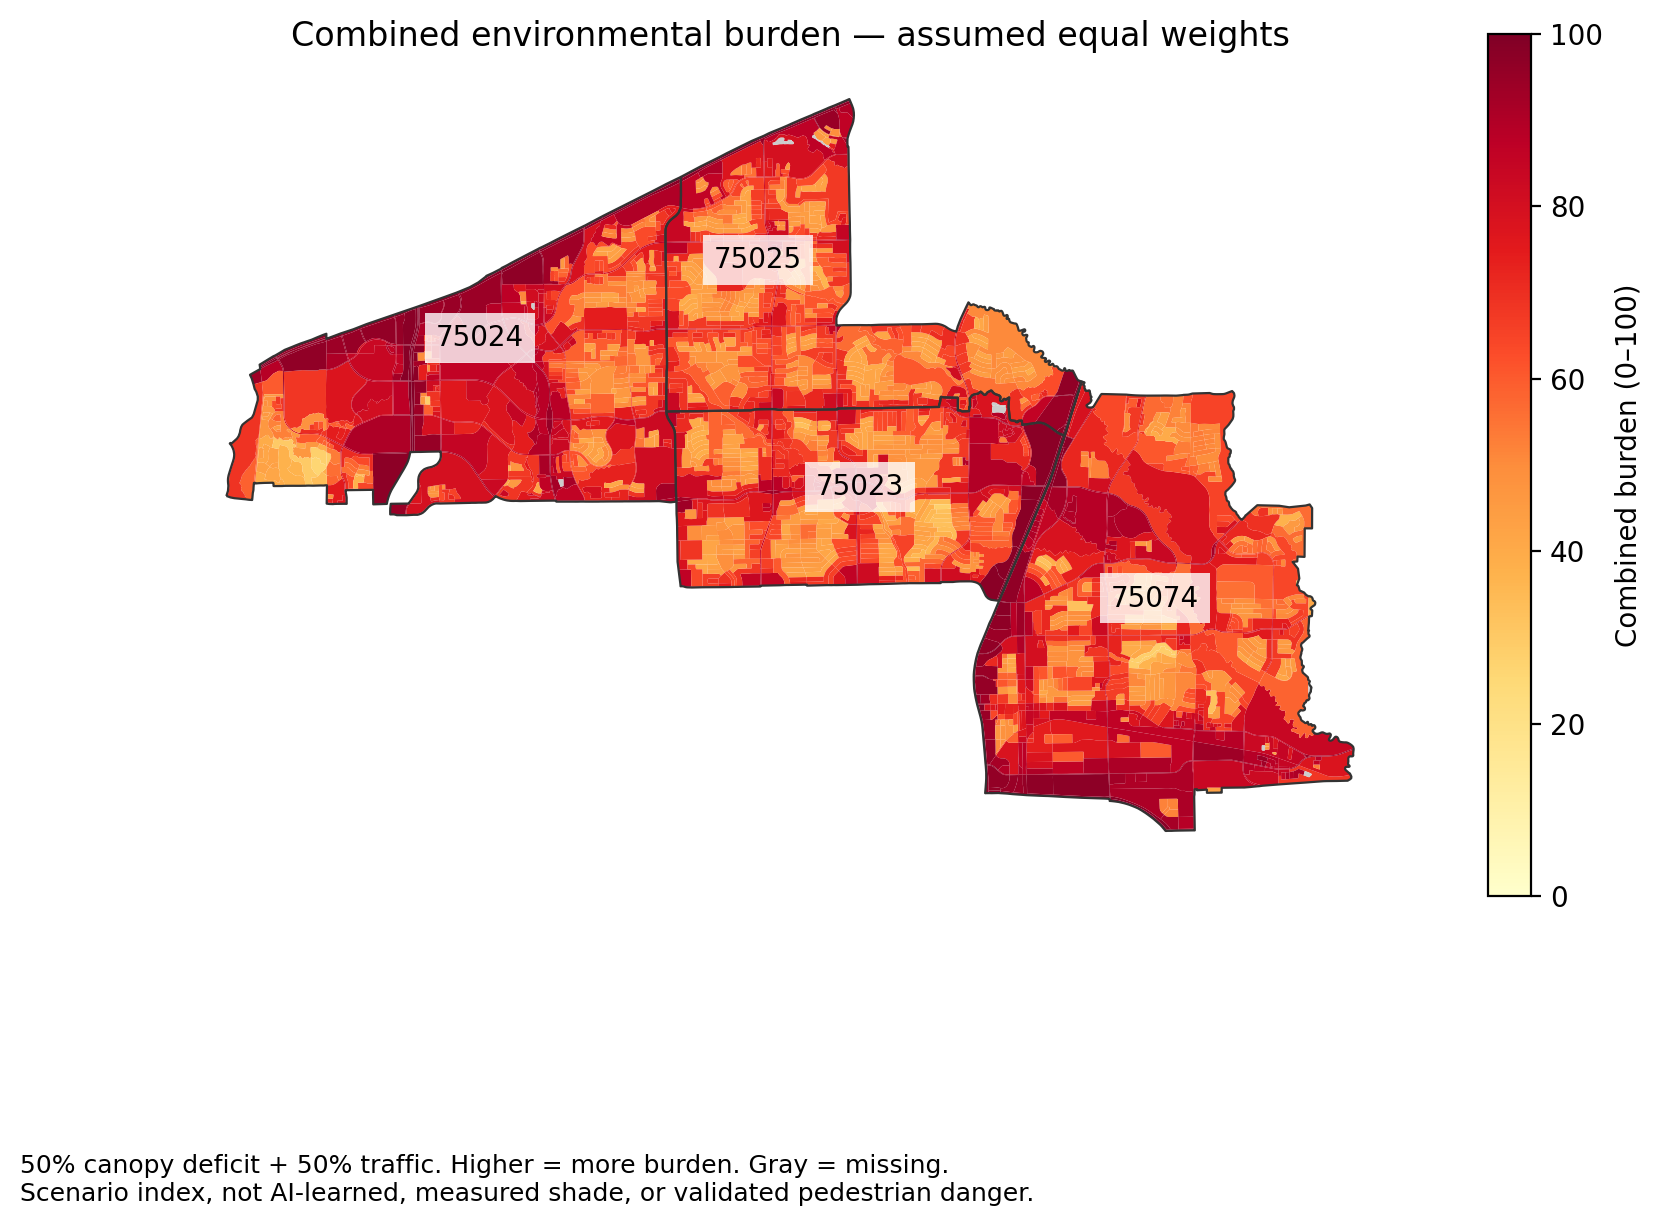

In [2]:
from IPython.display import Image,display
display(Image(filename=str(ROOT/'output/combined_block_index/combined_block_burden.png')))

The final HTML map also includes a switchable combined layer. To rebuild that map after source changes, run the next cell. The script reads your local basemap configuration without printing the key.

In [3]:
import geopandas as gpd
from package_clean_deliverables import render_map
base=ROOT/'output/clean_deliverables'
render_map(gpd.read_file(base/'block_environment.gpkg'),gpd.read_file(base/'walking_edges.gpkg'))
print('Updated final HTML map.')

Updated final HTML map.
